In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("../data/processed/telco_clean.csv")
df = pd.read_csv(DATA_PATH)

sns.set_theme(style="whitegrid")

Total customers: 7,043
Churn rate: 26.54%


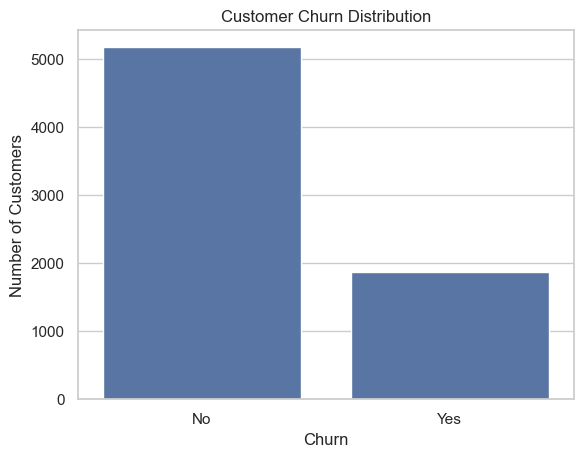

In [2]:
churn_rate = df["Churn"].eq("Yes").mean() * 100

print(f"Total customers: {len(df):,}")
print(f"Churn rate: {churn_rate:.2f}%")

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn Rate, dtype: float64


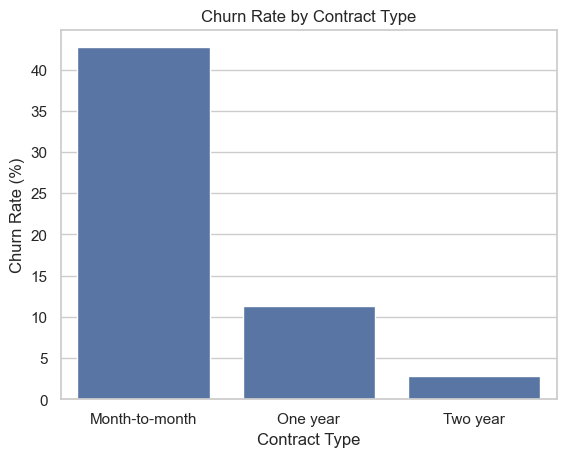

In [3]:
contract_churn = (
    df.groupby("Contract", observed=True)["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .sort_values(ascending=False)
    .rename("Churn Rate")
)

print(contract_churn.round(2))

sns.barplot(x=contract_churn.index, y=contract_churn.values)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.show()

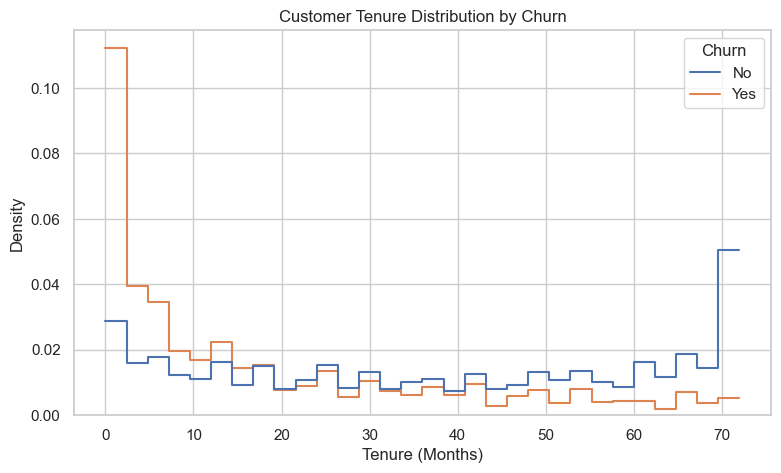

In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.show()

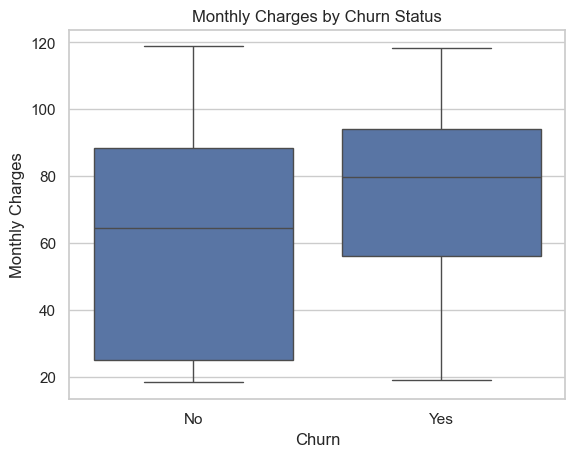

In [5]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

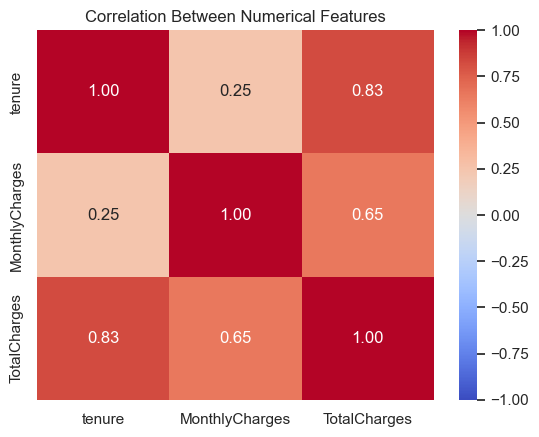

In [6]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.show()

InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn Rate, dtype: float64


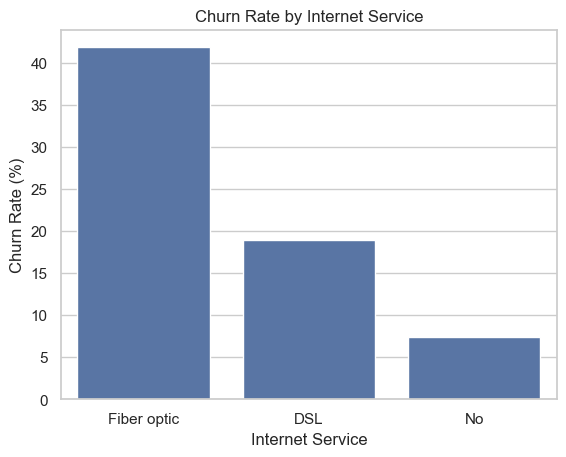

In [7]:
internet_churn = (
    df.groupby("InternetService", observed=True)["Churn"]
    .apply(lambda x: x.eq("Yes").mean() * 100)
    .sort_values(ascending=False)
    .rename("Churn Rate")
)

print(internet_churn.round(2))

sns.barplot(x=internet_churn.index, y=internet_churn.values)
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.show()